# MWR vs GOES-18 liquid water path at the Scripps Pier

This notebook continues Section 3d of `comparisons/seasonal_averages/check_seasonal_averages.ipynb`, the LWP row of the BAMS seasonal-averages table. It compares seasonal LWP statistics from the Pier microwave radiometer (MWR) with those from GOES-18. Its first task is to reproduce the statistic Seethala Chellappan sent on 16 Oct 2026:

| g m⁻² | Annual | AMJ | JAS | OND | JFM |
|---|---|---|---|---|---|
| MWR (epcmwrret2turnM1.c1) | 79.03 ± 55.86 | 89.74 ± 54.88 | 69.15 ± 49.11 | 52.26 ± 40.00 | 71.77 ± 56.93 |
| GOES-18 | 79.43 ± 53.49 | 89.84 ± 56.70 | 72.87 ± 55.13 | 34.17 ± 19.57 | 51.64 ± 35.80 |

Her email of 19 Oct 2026 (11:21 PDT) says how the statistic was made:

* **d)** Ground-based measurements were averaged to 30 min, to match the GOES-18 time resolution. Before averaging, LWP was removed wherever a surface precipitation was reported. For the KAZR, precipitating times and times with CTH > 2 km were removed before averaging.
* **i)** GOES-18 values come from the Scripps Pier grid box of a 0.2° × 0.2° data file.
* **j)** The same conditions were applied to the ground-based and the satellite data before the statistics: MWR and GOES-18 LWP 10–250 g m⁻²; GOES-18 LCF and ceilometer CFF > 10 %; GOES-18 TCF − LCF ≤ 10 %; GOES-18 SZA < 70°; GOES-18 and KAZR CTH ≤ 2 km; GOES-18 cloud optical depth > 2.

So the MWR is used **only at GOES-18 image times that pass every test**, and both statistics are taken over the same matched pairs. That answers the question in Andrew's reply ("Did you use only MWR LWP values at times when the GOES-18 retrieval passed your filters?"): yes. Section 3d of the seasonal-averages notebook did not do this. It applied ground-based stand-ins for every constraint, and no GOES-18 data.

**Data**

| What | Source | Notes |
|---|---|---|
| MWR LWP | `epcmwrret2turnM1.c1` `phys_lwp` (3-channel MWR, ~1.3 s) | `qc_phys_lwp` = 0 and `phys_qc_flag` = 0 (both flag the same 3.3 % of samples) |
| "Reported surface precipitation" (MWR) | `rain_intensity` in the same MWRRET v2 files (mm s⁻¹; source attribute `epcmwr3cM1.b1:rain_intensity`, the MWR3C's own rain sensor) | It is my inference that this is the field she means: it is the only precipitation field in the MWRRET v2 files. It has no `qc_` field. |
| Ceilometer CFF | `epcceilM1.b1` (16 s): base ≤ 2 km with `qc_first_cbh` = 0, as in 3d | 2 km = the GOES-18 "low" level (0–2 km, file attribute `level1`) |
| KAZR CTH | `epcarsclkazr1kolliasM1.c1` `cloud_layer_top_height`: top of the highest layer (4 s), as in 3d | no `qc_` field exists for the layer tops |
| "Precipitating times" (KAZR) | `precip_mean` in the same ARSCL files (rain gauge, mm h⁻¹), `qc_precip_mean` = 0 | inference, as for the MWR |
| GOES-18 | `epcvisstgridg18minnisX1.c1` (SatCORPS/VISST, Minnis), half-hourly images, the box containing the Pier | **0.5° × 0.5° boxes, not her 0.2°.** The ARM grid box (32.5–33.0 N, 117.5–117.0 W) is ~6× larger in area than hers and about half land. |

**What cannot be matched exactly:** (1) her 0.2° file is not this ARM grid; (2) which precipitation fields she used (the email names none); (3) how her 30-min bins line up with the image times; (4) whether she screened the MWR with QC. Each of these has a setting, and Section 4 shows how much each one moves the numbers.

## Running it

1. Download the inputs from the EPCAPE folder: `python comparisons/seasonal_averages/download_data.py --only lwp_mwrret2_M1 cbh_ceil_M1 cloud_arscl_M1` (if not already there), then `python comparisons/lwp_mwr_vs_goes/download_data.py`. The second command fetches the GOES-18 grid as complete daily files, about 3.5 GB in `data/arm/epcvisstgridg18minnisX1.c1/`. It reduces them to the 3 × 3 boxes around the Pier (`processed/goes18_visst_pier_X1_*.nc`, 34 MB), then to the Pier box with only the variables used here (`processed/goes18_visst_pierbox_X1_*.nc`, 10 MB). This notebook reads only the last file. The daily files were deleted on 19 Oct 2026 to save space, so rebuilding either file needs the download again. It also fetches the two precipitation fields.
2. Run all cells. The MWRRET v2 record (~22 million samples) takes most of the run time and memory (~2 GB).

In [1]:
# --- Setup: make the EPCAPE package importable -------------------------------
# The EPCAPE folder is itself the Python package (config.yaml at its top level), so its PARENT folder goes on
# sys.path. Same code as the seasonal-averages notebook.
import os
import sys
from pathlib import Path


def find_repo_root(start: Path = Path.cwd()) -> Path:
    # Walk up from the notebook's folder to the EPCAPE folder (holds config.yaml and __init__.py)
    for p in [start, *start.parents]:
        if (p / "config.yaml").is_file() and (p / "__init__.py").is_file():
            return p
    raise FileNotFoundError(f"Could not find the EPCAPE folder above {start}")


REPO = find_repo_root()
if str(REPO.parent) not in sys.path:
    sys.path.insert(0, str(REPO.parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from EPCAPE.analysis_tools.derived import git_revision
from EPCAPE.analysis_tools.products import load_product
from EPCAPE.download_data.config import active_machine
from EPCAPE.plotting import COLORS, INK, INK_2, INK_3, savefig, use_style
from EPCAPE.comparisons.seasonal_averages import quantities as Q
from EPCAPE.comparisons.seasonal_averages import seasonal as S
from EPCAPE.comparisons.lwp_mwr_vs_goes import goes18 as G
from EPCAPE.comparisons.lwp_mwr_vs_goes import matching as M

use_style()
pd.set_option("display.width", 220, "display.max_columns", 30, "display.max_colwidth", 90)
MACHINE = active_machine()
GIT_REVISION = git_revision()
FIG_DIR = REPO / "comparisons" / "lwp_mwr_vs_goes" / "figures"
FIG_DIR.mkdir(exist_ok=True)
print(f"EPCAPE folder: {REPO}\nData folder: {MACHINE.data_root}\ngit revision: {GIT_REVISION}")

EPCAPE folder: /Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE
Data folder: /Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/data
git revision: 3d72d43-dirty


In [2]:
# --- Settings: every choice that changes a number is set here ------------------------------------------------------
# Seethala's constraints (email of 19 Oct 2026, item j), with her inequalities as written
LWP_RANGE_GM2 = (10.0, 250.0)  # MWR and GOES-18 LWP: 10 <= LWP <= 250 g m-2 (inclusive)
CF_MIN = 0.10  # GOES-18 LCF > 10 % and ceilometer CFF > 10 % (strict)
NONLOW_MAX = 0.10  # GOES-18 TCF - LCF <= 10 %
SZA_MAX_DEG = 70.0  # GOES-18 SZA < 70 deg (strict)
CTH_MAX_KM = 2.0  # GOES-18 and KAZR CTH <= 2 km
COD_MIN = 2.0  # GOES-18 cloud optical depth > 2 (strict)

# The time matching (item d: "averaged ground-based measurements to 30-minutes")
WINDOW_MIN = 30.0  # minutes: length of the ground-based average that goes with one GOES-18 image
WINDOW_ALIGNMENT = "bin"  # "bin": the clock's 30-min bin holding the nominal image time ([hh:00, hh:30) ...);
#                           "centered": [scan time - 15 min, scan time + 15 min) at the Pier box (matching.image_windows)

# MWR (MWRRET v2 phys_lwp, ~1.3 s)
MWR_QC = "qc0"  # "qc0": qc_phys_lwp = 0 and phys_qc_flag = 0 (the user's QC = 0 rule); "none": every finite sample
MWR_RAIN_SCREEN = "mwr_rain_sensor"  # which samples "with a reported surface precipitation" are removed:
#   "mwr_rain_sensor": rain_intensity > 0 in the MWRRET v2 file (MWR3C rain sensor), that sample only
#   "parsivel_30min":  any Pier Parsivel (LD M1, QC = 0) rain within ±30 min (the seasonal-averages rain screen)
#   "both":            either of the two;  "none": no rain screen
MWR_NEGATIVE = "keep"  # LWP < 0 (clear-sky retrieval noise) before averaging: "keep", "drop" or "zero"
MWR_MIN_COVERAGE = 0.5  # a 30-min MWR mean needs >= 50 % of the samples a full window holds (after the screens)

# Ceilometer CFF (cloud frequency fraction, Pier ceilometer epcceilM1.b1, 16 s)
CFF_LOW_MAX_M = 2000.0  # "low" cloud for CFF: first base <= 2 km (= GOES-18 "low", 0-2 km); np.inf = any base
CFF_MIN_COVERAGE = 0.5  # a window's CFF needs a known cloud state for >= 50 % of its samples (as in 3c/3d)

# KAZR (ARSCL highest layer top, 4 s)
KAZR_PRECIP_SCREEN = "arscl_rain_gauge"  # "arscl_rain_gauge": precip_mean > 0 (QC = 0) in the ARSCL file; "none"
KAZR_CTH_RULE = "literal"  # what "KAZR CTH <= 2 km" means after her step d (matching.kazr_window_cth_m):
#   "literal":  precipitating samples and tops > 2 km are removed, then averaged; the pair needs a value, i.e. at
#               least one non-precipitating sample with a layer topped at <= 2 km in the window
#   "mean_all": the 30-min mean of all (non-precipitating) layer tops must be <= 2 km;  "none": KAZR not used

# GOES-18 (epcvisstgridg18minnisX1.c1, the box containing the Pier)
GOES_CLOUD_KIND = "total"  # cld_type for COD and CTH: "total" (all clouds; the satellite sees the top-most) or "water"
#   LWP is always water_path of the water phase; LCF / TCF are cloud_percentage_level "low" (0-2 km) / "total".

# Seethala's numbers (email of 16 Oct 2026), rows mapped onto the sheet's season columns:
# Annual -> EPCAPE, AMJ -> Spring, JAS -> Summer, OND -> Fall, JFM -> Winter (FM 2023 + JF 2024)
SEETHALA = pd.DataFrame({"MWR_mean": [79.03, 89.74, 69.15, 52.26, 71.77], "MWR_std": [55.86, 54.88, 49.11, 40.00, 56.93],
                         "GOES18_mean": [79.43, 89.84, 72.87, 34.17, 51.64],
                         "GOES18_std": [53.49, 56.70, 55.13, 19.57, 35.80]}, index=S.SEASON_ORDER)
SEETHALA_LABELS = dict(zip(S.SEASON_ORDER, ["Annual", "AMJ", "JAS", "OND", "JFM"]))

OUT_DIR = MACHINE.processed_dir() / "derived" / "lwp_mwr_vs_goes"
OUT_DIR.mkdir(parents=True, exist_ok=True)
WIDTH = pd.Timedelta(minutes=WINDOW_MIN)
SETTINGS = {k: v for k, v in dict(globals()).items() if k.isupper() and k not in ("REPO", "MACHINE", "SETTINGS", "SEETHALA")
            and not isinstance(v, (pd.DataFrame, pd.Timedelta, Path))}
SETTINGS

{'COLORS': {'MFRSR': '#2a78d6', 'SPHOT': '#eb6834', 'MWR': '#1baf7a'},
 'INK': '#0b0b0b',
 'INK_2': '#52514e',
 'INK_3': '#8a8984',
 'Q': <module 'EPCAPE.comparisons.seasonal_averages.quantities' from '/Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/comparisons/seasonal_averages/quantities.py'>,
 'S': <module 'EPCAPE.comparisons.seasonal_averages.seasonal' from '/Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/comparisons/seasonal_averages/seasonal.py'>,
 'G': <module 'EPCAPE.comparisons.lwp_mwr_vs_goes.goes18' from '/Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/comparisons/lwp_mwr_vs_goes/goes18.py'>,
 'M': <module 'EPCAPE.comparisons.lwp_mwr_vs_goes.matching' from '/Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/comparisons/lwp_mwr_vs_goes/matching.py'>,
 'GIT_REVISION': '3d72d43-dirty',
 'LWP_RANGE_GM2': (10.0, 250.0),
 'CF_MIN': 0.1,
 'NONLOW_MAX': 0.1,
 'SZA_MAX_DEG': 70.0,
 'CTH_MAX_KM': 2.0,
 'COD_MIN': 2.0,
 'WINDOW_MIN': 30.

## 1. The records

Every record is reduced to what the constraints need, at its own time resolution. The averaging over each GOES-18 image's 30-min window comes in Section 2.

**Precipitation fields.** The email names no precipitation field. Two candidates sit inside the files she names, and both are used here:
* MWRRET v2 `rain_intensity` is copied from the MWR3C's own rain sensor. It is the only precipitation field in the MWRRET v2 files.
* ARSCL `precip_mean` is the rain gauge carried in the KAZR-ARSCL files.

The Pier Parsivel screen (±30 min) of the seasonal-averages notebook is kept as an alternative. A missing or QC-failed precipitation value counts as dry, as in `Q.near_rain`.

In [3]:
# =============================================================================
# Section 1: load every record
# =============================================================================
# --- 1a. MWRRET v2 LWP (every sample) with its QC result and the two precipitation screens -------------------------
ds = load_product("lwp_mwrret2_M1")  # phys_lwp (g m-2), qc_phys_lwp, phys_qc_flag, cbh_detected, detection_status
mwr_time = pd.DatetimeIndex(ds["time"].values)
MWR = pd.DataFrame({
    "lwp_gm2": ds["phys_lwp"].values.astype(float),
    # QC = 0 on both QC fields (see Q.lwp_qc_rain_free_gm2's docstring: they flag the same 3.3 % of samples)
    "qc_ok": ((ds["qc_phys_lwp"].values == 0) & (ds["phys_qc_flag"].values == 0)),
}, index=mwr_time)
del ds

# rain_intensity (mm s-1) from the same MWRRET v2 files; same datastream, so the time stamps should be identical
rain_ds = load_product("rain_mwrret2_M1")
rain_mwr = Q.to_series(rain_ds["rain_intensity"])
del rain_ds
rain_mwr = rain_mwr[~rain_mwr.index.duplicated()]
same_times = rain_mwr.index.equals(MWR.index)
if not same_times:  # fall back to the nearest rain value within 2 s
    rain_mwr = rain_mwr.sort_index().reindex(MWR.index, method="nearest", tolerance=pd.Timedelta(seconds=2))
MWR["mwr_rain"] = (rain_mwr.to_numpy() > 0)  # NaN (missing) -> False = dry
print(f"MWRRET v2: {len(MWR):,} samples, {MWR['qc_ok'].mean():.1%} pass QC = 0; rain_intensity on identical time stamps: "
      f"{same_times}; rain_intensity > 0 at {MWR['mwr_rain'].mean():.2%} of samples, missing at "
      f"{np.mean(~np.isfinite(rain_mwr.to_numpy())):.2%}")
del rain_mwr

# Pier Parsivel (LD M1) rain rate, QC = 0, 1 min: the ±30-min screen of the seasonal-averages notebook
ld_m1 = load_product("rain_ld_M1")
pier_rain = Q.to_series(Q.qc0_values(ld_m1, "precip_rate")[0])
del ld_m1
MWR["parsivel_30min"] = Q.near_rain(pier_rain, MWR.index, window_min=30.0)
print(f"Within ±30 min of Parsivel rain: {MWR['parsivel_30min'].mean():.2%} of samples. MWR rain sensor > 0 and "
      f"Parsivel ±30 min agree on {np.mean(MWR['mwr_rain'] == MWR['parsivel_30min']):.2%} of samples; "
      f"rain-sensor samples outside the Parsivel window: {np.mean(MWR['mwr_rain'] & ~MWR['parsivel_30min']):.3%}")
MWR_DT = M.median_interval(MWR.index)  # ~1.3 s

# --- 1b. Ceilometer low-cloud state per 16-s sample (1 = base <= CFF_LOW_MAX_M, 0 = clear or higher base, NaN unknown)
ceil = load_product("cbh_ceil_M1")
PIER_LAT, PIER_LON = float(ceil["lat"].values.ravel()[0]), float(ceil["lon"].values.ravel()[0])  # deg N, deg E
CEIL_STATE = {h: Q.ceilometer_low_cloud_state(ceil, max_cbh_m=h) for h in sorted({CFF_LOW_MAX_M, 3500.0, np.inf})}
del ceil

# --- 1c. KAZR-ARSCL: top of the highest layer per 4-s sample (-1 = no layer), and the ARSCL rain gauge -------------
arscl = load_product("cloud_arscl_M1")
HIGHEST_TOP_M = Q.arscl_highest_top_m(arscl)
del arscl
pr = load_product("precip_arscl_M1")
gauge_mm_h, _ = Q.qc0_values(pr, "precip_mean")  # mm h-1, QC = 0 (bit 3 = missing in the input)
gauge = Q.to_series(gauge_mm_h)
del pr
gauge = gauge[~gauge.index.duplicated()].sort_index().reindex(HIGHEST_TOP_M.index, method="nearest",
                                                             tolerance=pd.Timedelta(seconds=2))
KAZR_PRECIP = {"arscl_rain_gauge": (gauge.to_numpy() > 0), "none": np.zeros(len(HIGHEST_TOP_M), dtype=bool)}
print(f"KAZR-ARSCL: {len(HIGHEST_TOP_M):,} samples; rain gauge > 0 at {KAZR_PRECIP['arscl_rain_gauge'].mean():.2%}; "
      f"highest top: no layer {np.mean(HIGHEST_TOP_M.to_numpy() == -1):.1%}, <= 2 km "
      f"{np.mean((HIGHEST_TOP_M.to_numpy() >= 0) & (HIGHEST_TOP_M.to_numpy() <= 2000)):.1%}, > 2 km "
      f"{np.mean(HIGHEST_TOP_M.to_numpy() > 2000):.1%}")
del gauge, gauge_mm_h

# --- 1d. GOES-18: the box containing the Pier (processed/goes18_visst_pierbox_X1_*.nc) ------------------------------
GOES_DS = G.load_pier_box()  # the Pier box only, with the variables used here (goes18.extract_pier_box)
print("Pier box centre", float(GOES_DS["latitude"][0]), "N,", float(GOES_DS["longitude"][0]), "E (0.5 deg box)")
GOES_BOX = {kind: G.box_table(GOES_DS, i=0, j=0, cloud_kind=kind) for kind in ("total", "water")}
g_ = GOES_BOX["total"]
print(f"GOES-18 images: {len(g_):,} ({g_.index.min():%Y-%m-%d} to {g_.index.max():%Y-%m-%d}); LWP present in "
      f"{g_['lwp_gm2'].notna().mean():.1%}; scan reaches the Pier box {(g_['scan_time'] - g_.index).median()} after "
      f"the nominal image time")
# the file's solar zenith angle vs the NOAA equations at the scan time (both are calculations)
sza_noaa = Q.solar_zenith_deg(g_["scan_time"].fillna(pd.Series(g_.index, index=g_.index)), PIER_LAT, PIER_LON)
d_ = g_["sza_deg"].to_numpy() - sza_noaa
day_ = sza_noaa < 80
print(f"SZA, GOES-18 file - NOAA at the Pier and scan time (SZA < 80°): median {np.nanmedian(d_[day_]):+.2f}°, "
      f"95th percentile |difference| {np.nanpercentile(np.abs(d_[day_]), 95):.2f}° (the box centre is ~13 km from the Pier)")
del g_, sza_noaa, d_, day_

MWRRET v2: 22,047,667 samples, 96.7% pass QC = 0; rain_intensity on identical time stamps: True; rain_intensity > 0 at 0.69% of samples, missing at 1.64%


Within ±30 min of Parsivel rain: 8.44% of samples. MWR rain sensor > 0 and Parsivel ±30 min agree on 92.24% of samples; rain-sensor samples outside the Parsivel window: 0.003%


KAZR-ARSCL: 7,884,000 samples; rain gauge > 0 at 2.48%; highest top: no layer 52.6%, <= 2 km 22.2%, > 2 km 25.2%


Pier box centre 32.75 N, -117.25 E (0.5 deg box)
GOES-18 images: 17,423 (2023-02-15 to 2024-02-14); LWP present in 88.3%; scan reaches the Pier box 0 days 00:01:26.998883840 after the nominal image time
SZA, GOES-18 file - NOAA at the Pier and scan time (SZA < 80°): median -0.04°, 95th percentile |difference| 0.37° (the box centre is ~13 km from the Pier)


## 2. One row per GOES-18 image: the matched pair table

`build_pairs` turns every record into one value per GOES-18 image:
* **MWR LWP**: the mean of the screened samples in the image's 30-min window. The window needs ≥ `MWR_MIN_COVERAGE` of a full window's samples.
* **Ceilometer CFF**: the fraction of the window's known 16-s samples with a base ≤ `CFF_LOW_MAX_M`.
* **KAZR CTH**: the two window statistics of `matching.kazr_window_cth_m`.
* **GOES-18**: the image's values for the Pier box.

`matching.constraint_masks` then applies item j, with her inequalities as written.

In [4]:
# =============================================================================
# Section 2: the matched pair table and her constraints
# =============================================================================
def mwr_samples(*, qc=MWR_QC, rain=MWR_RAIN_SCREEN, negative=MWR_NEGATIVE) -> pd.Series:
    # MWR LWP samples (g m-2) left after the QC choice, the precipitation screen and the treatment of LWP < 0
    # .copy(): to_numpy() can return a VIEW of the column, and the &= below would then overwrite MWR["qc_ok"]
    keep = MWR["qc_ok"].to_numpy().copy() if qc == "qc0" else np.ones(len(MWR), dtype=bool)
    if rain in ("mwr_rain_sensor", "both"):
        keep &= ~MWR["mwr_rain"].to_numpy()
    if rain in ("parsivel_30min", "both"):
        keep &= ~MWR["parsivel_30min"].to_numpy()
    if rain not in ("mwr_rain_sensor", "parsivel_30min", "both", "none"):
        raise ValueError(f"unknown rain screen {rain!r}")
    lwp = MWR["lwp_gm2"][keep]
    if negative == "drop":
        lwp = lwp[lwp >= 0]
    elif negative == "zero":
        lwp = lwp.clip(lower=0.0)
    elif negative != "keep":
        raise ValueError(f"unknown MWR_NEGATIVE {negative!r}")
    return lwp


def build_pairs(*, alignment=WINDOW_ALIGNMENT, qc=MWR_QC, rain=MWR_RAIN_SCREEN, negative=MWR_NEGATIVE,
                cff_low_max_m=CFF_LOW_MAX_M, kazr_precip=KAZR_PRECIP_SCREEN, cloud_kind=GOES_CLOUD_KIND) -> pd.DataFrame:
    # One row per GOES-18 image (index = nominal image time, UTC): GOES-18 Pier-box values + 30-min ground averages
    images = GOES_BOX[cloud_kind]
    starts = M.image_windows(images, alignment=alignment, width_min=WINDOW_MIN)  # one window per image
    # MWR: mean of the screened samples; NaN when the window holds < MWR_MIN_COVERAGE of a full window's samples
    w = M.window_means(mwr_samples(qc=qc, rain=rain, negative=negative), starts, WIDTH)
    mwr_mean = w["mean"].where(w["n"] >= MWR_MIN_COVERAGE * (WIDTH / MWR_DT))
    # ceilometer CFF over the same window
    cff = M.state_fraction(CEIL_STATE[cff_low_max_m], starts, WIDTH, min_coverage=CFF_MIN_COVERAGE)
    # KAZR: precipitation removed, then the window statistics of the highest layer top
    kz = M.kazr_window_cth_m(HIGHEST_TOP_M, KAZR_PRECIP[kazr_precip], starts, WIDTH, cth_max_m=1000.0 * CTH_MAX_KM)
    return pd.DataFrame({
        "window_start": starts,
        "goes_lwp_gm2": images["lwp_gm2"].to_numpy(), "goes_lcf": images["lcf"].to_numpy(),
        "goes_tcf": images["tcf"].to_numpy(), "goes_sza_deg": images["sza_deg"].to_numpy(),
        "goes_cth_km": images["cth_km"].to_numpy(), "goes_cod": images["cod"].to_numpy(),
        "goes_re_um": images["re_um"].to_numpy(),
        "mwr_lwp_gm2": mwr_mean.to_numpy(), "mwr_n": w["n"].to_numpy(), "ceil_cff": cff.to_numpy(),
        "kazr_cth_low_mean_m": kz["cth_low_mean_m"].to_numpy(), "kazr_cth_all_mean_m": kz["cth_all_mean_m"].to_numpy(),
    }, index=images.index)


def masks_for(pairs, kazr_rule=KAZR_CTH_RULE):
    # item j, one boolean mask per constraint (matching.constraint_masks), with the settings' thresholds
    return M.constraint_masks(pairs, lwp_range_gm2=LWP_RANGE_GM2, cf_min=CF_MIN, nonlow_max=NONLOW_MAX,
                              sza_max_deg=SZA_MAX_DEG, cth_max_km=CTH_MAX_KM, cod_min=COD_MIN, kazr_rule=kazr_rule)


def matched_stats(pairs, keep):
    # seasonal mean, std, median, n of the MWR and of GOES-18 over the SAME selected pairs
    sel = pairs[keep]
    return {"MWR": S.seasonal_stats(sel["mwr_lwp_gm2"]), "GOES-18": S.seasonal_stats(sel["goes_lwp_gm2"])}


def pm_n(st):
    # 'mean ± std (n)' per season
    return [f"{S.format_pm(m, s)} ({int(n)})" for m, s, n in zip(st["mean"], st["std"], st["n"])]


PAIRS = build_pairs()
MASKS = masks_for(PAIRS)
KEEP = M.all_constraints(MASKS)
print(f"{len(PAIRS):,} GOES-18 images; MWR 30-min mean available for {PAIRS['mwr_lwp_gm2'].notna().mean():.1%}; "
      f"pairs passing every constraint: {KEEP.sum():,}")
PAIRS.loc[KEEP].to_csv(OUT_DIR / "matched_pairs_default.csv")  # the selected pairs, for checking against hers

17,423 GOES-18 images; MWR 30-min mean available for 86.7%; pairs passing every constraint: 1,349


## 3. The statistic with her constraints, next to hers

Each cell holds mean ± std over the matched 30-min pairs, with the number of pairs in brackets. Our MWR and GOES-18 rows use **the same pairs**.

In [5]:
# =============================================================================
# Section 3: our matched statistic vs Seethala's
# =============================================================================
ST = matched_stats(PAIRS, KEEP)
RESULT = pd.DataFrame({
    "ours, MWR": pm_n(ST["MWR"]), "ours, GOES-18 (0.5° ARM box)": pm_n(ST["GOES-18"]),
    "Seethala, MWR": [S.format_pm(m, s) for m, s in zip(SEETHALA["MWR_mean"], SEETHALA["MWR_std"])],
    "Seethala, GOES-18 (0.2° box)": [S.format_pm(m, s) for m, s in zip(SEETHALA["GOES18_mean"], SEETHALA["GOES18_std"])],
}, index=[f"{s} ({SEETHALA_LABELS[s]})" for s in S.SEASON_ORDER]).T
display(Markdown("**LWP (g m⁻²): mean ± std (n matched 30-min pairs), all of her constraints**"))
display(RESULT)

DIFF = pd.DataFrame({
    "ours MWR - her MWR": ST["MWR"]["mean"].values - SEETHALA["MWR_mean"].values,
    "ours GOES-18 - her GOES-18": ST["GOES-18"]["mean"].values - SEETHALA["GOES18_mean"].values,
    "ours: MWR - GOES-18": ST["MWR"]["mean"].values - ST["GOES-18"]["mean"].values,
    "hers: MWR - GOES-18": SEETHALA["MWR_mean"].values - SEETHALA["GOES18_mean"].values,
}, index=S.SEASON_ORDER).round(1).T
display(Markdown("**Differences in the mean (g m⁻²; positive = the first one higher)**"))
display(DIFF)

**LWP (g m⁻²): mean ± std (n matched 30-min pairs), all of her constraints**

,EPCAPE (Annual),Spring (AMJ),Summer (JAS),Fall (OND),Winter (JFM)
"ours, MWR",81 ± 55 (1349),89 ± 56 (717),75 ± 53 (490),57 ± 44 (58),64 ± 53 (84)
"ours, GOES-18 (0.5° ARM box)",75 ± 51 (1349),85 ± 53 (717),68 ± 49 (490),54 ± 36 (58),55 ± 41 (84)
"Seethala, MWR",79 ± 56,90 ± 55,69 ± 49,52 ± 40,72 ± 57
"Seethala, GOES-18 (0.2° box)",79 ± 53,90 ± 57,73 ± 55,34 ± 20,52 ± 36


**Differences in the mean (g m⁻²; positive = the first one higher)**

,EPCAPE,Spring,Summer,Fall,Winter
ours MWR - her MWR,1.9,-1.0,6.1,5.2,-7.8
ours GOES-18 - her GOES-18,-4.0,-5.0,-5.0,19.6,2.9
ours: MWR - GOES-18,5.5,3.9,7.4,3.7,9.4
hers: MWR - GOES-18,-0.4,-0.1,-3.7,18.1,20.1


### 3b. Which constraint removes which pairs

The ladder adds her constraints one at a time, in her order. Every step shows the MWR mean and the GOES-18 mean over the pairs still kept, with the number of pairs. The second table removes **one** constraint at a time from the full set, to show how much each one matters given all the others.

In [6]:
# =============================================================================
# Section 3b: the constraint ladder and leave-one-out
# =============================================================================
def mean_pair(st_mwr, st_goes):
    # 'MWR / GOES-18 (n)' per season
    return [f"{m:.1f} / {g:.1f} ({int(n)})" if n else "–"
            for m, g, n in zip(st_mwr["mean"], st_goes["mean"], st_mwr["n"])]


# both LWP values must exist for a pair to count at all (step 0)
base = PAIRS["mwr_lwp_gm2"].notna().to_numpy() & PAIRS["goes_lwp_gm2"].notna().to_numpy()
rows, keep_ = {}, base.copy()
st0 = matched_stats(PAIRS, keep_)
rows["0. GOES-18 LWP and a 30-min MWR mean both exist"] = mean_pair(st0["MWR"], st0["GOES-18"])
for k, (name, m) in enumerate(MASKS.items(), 1):
    keep_ &= m
    st_ = matched_stats(PAIRS, keep_)
    rows[f"{k}. + {name}"] = mean_pair(st_["MWR"], st_["GOES-18"])
LADDER = pd.DataFrame(rows, index=S.SEASON_ORDER).T
LADDER.loc["Seethala (email)"] = [f"{a:.1f} / {b:.1f}" for a, b in zip(SEETHALA["MWR_mean"], SEETHALA["GOES18_mean"])]
display(Markdown("**MWR / GOES-18 mean LWP (g m⁻²) and pairs kept, as her constraints are added**"))
display(LADDER)

rows = {}
for name in MASKS:
    keep_ = base & M.all_constraints(MASKS, skip=(name,))
    st_ = matched_stats(PAIRS, keep_)
    rows[f"all but: {name}"] = mean_pair(st_["MWR"], st_["GOES-18"])
rows["all constraints"] = mean_pair(ST["MWR"], ST["GOES-18"])
display(Markdown("**Leave one constraint out (MWR / GOES-18 mean, n pairs)**"))
display(pd.DataFrame(rows, index=S.SEASON_ORDER).T)
del keep_, st_, st0

**MWR / GOES-18 mean LWP (g m⁻²) and pairs kept, as her constraints are added**

,EPCAPE,Spring,Summer,Fall,Winter
0. GOES-18 LWP and a 30-min MWR mean both exist,52.4 / 46.4 (13556),89.7 / 67.2 (3910),50.4 / 34.8 (3841),22.2 / 37.1 (2727),34.3 / 42.8 (3078)
1. + MWR LWP 10-250 g m-2,69.0 / 56.9 (7398),96.2 / 76.6 (2528),60.4 / 40.7 (2416),40.2 / 48.9 (1180),57.6 / 56.0 (1274)
2. + GOES-18 LWP 10-250 g m-2,73.1 / 58.2 (6346),96.8 / 73.8 (2349),66.6 / 46.7 (1932),42.2 / 45.0 (900),59.8 / 55.9 (1165)
3. + GOES-18 LCF > 10 %,75.5 / 59.6 (5776),97.6 / 73.9 (2295),67.7 / 48.6 (1768),45.0 / 44.0 (719),60.6 / 57.5 (994)
4. + ceilometer CFF > 10 %,79.5 / 61.6 (5351),98.6 / 74.4 (2265),69.1 / 49.2 (1680),50.8 / 46.1 (557),67.8 / 61.9 (849)
5. + GOES-18 TCF - LCF <= 10 %,81.1 / 62.4 (4401),99.2 / 74.3 (2012),71.6 / 51.8 (1464),51.6 / 48.1 (458),61.3 / 58.1 (467)
6. + GOES-18 SZA < 70 deg,72.2 / 69.1 (1605),82.7 / 80.5 (798),67.2 / 61.7 (586),40.9 / 46.1 (113),54.2 / 48.4 (108)
7. + GOES-18 CTH <= 2 km,72.2 / 69.1 (1605),82.7 / 80.5 (798),67.2 / 61.7 (586),40.9 / 46.1 (113),54.2 / 48.4 (108)
8. + KAZR CTH <= 2 km,80.0 / 74.5 (1371),88.7 / 84.7 (718),73.9 / 66.5 (502),53.0 / 49.7 (65),62.7 / 53.6 (86)
9. + GOES-18 COD > 2,81.0 / 75.5 (1349),88.8 / 84.8 (717),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84)


**Leave one constraint out (MWR / GOES-18 mean, n pairs)**

,EPCAPE,Spring,Summer,Fall,Winter
all but: MWR LWP 10-250 g m-2,94.8 / 79.8 (1484),106.5 / 89.7 (802),86.5 / 71.9 (529),56.6 / 53.1 (59),66.7 / 56.2 (94)
all but: GOES-18 LWP 10-250 g m-2,82.6 / 78.3 (1370),91.8 / 90.1 (736),75.0 / 67.6 (492),57.5 / 53.8 (58),63.9 / 54.5 (84)
all but: GOES-18 LCF > 10 %,80.8 / 75.3 (1353),88.7 / 84.8 (718),75.1 / 67.8 (491),56.8 / 52.6 (60),63.9 / 54.5 (84)
all but: ceilometer CFF > 10 %,81.0 / 75.6 (1353),88.8 / 84.8 (717),75.3 / 68.2 (494),57.5 / 53.8 (58),63.9 / 54.5 (84)
all but: GOES-18 TCF - LCF <= 10 %,79.4 / 73.2 (1522),89.0 / 84.6 (769),71.3 / 63.0 (551),59.0 / 55.6 (64),67.4 / 58.1 (138)
all but: GOES-18 SZA < 70 deg,90.2 / 66.3 (3765),105.9 / 76.9 (1841),77.8 / 54.8 (1282),69.8 / 51.4 (263),69.9 / 64.4 (379)
all but: GOES-18 CTH <= 2 km,81.0 / 75.5 (1349),88.8 / 84.8 (717),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84)
all but: KAZR CTH <= 2 km,73.4 / 70.3 (1571),83.2 / 81.0 (792),68.3 / 62.9 (573),43.0 / 48.7 (104),56.5 / 50.4 (102)
all but: GOES-18 COD > 2,80.0 / 74.5 (1371),88.7 / 84.7 (718),73.9 / 66.5 (502),53.0 / 49.7 (65),62.7 / 53.6 (86)
all constraints,81.0 / 75.5 (1349),88.8 / 84.8 (717),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84)


## 4. Choices the email does not settle

Each row changes **one** setting from the defaults of the settings cell. Every row keeps all of her constraints. The last two columns give the mean |ours − hers| over the four seasons, for the MWR and for GOES-18. A choice that brings the MWR closer to her MWR value is the more likely reading of her method. The GOES-18 values are also limited by the box size (0.5° here, 0.2° hers), and no setting changes that.

In [7]:
# =============================================================================
# Section 4: sensitivity to the choices the email leaves open
# =============================================================================
VARIANTS = {
    "default (settings cell)": {},
    "window: centred on the scan time": dict(alignment="centered"),
    "MWR rain: Parsivel ±30 min instead of the MWR rain sensor": dict(rain="parsivel_30min"),
    "MWR rain: both screens": dict(rain="both"),
    "MWR rain: none": dict(rain="none"),
    "MWR QC: none": dict(qc="none"),
    "MWR LWP < 0 dropped": dict(negative="drop"),
    "MWR LWP < 0 set to 0": dict(negative="zero"),
    "CFF low cloud: base <= 3.5 km": dict(cff_low_max_m=3500.0),
    "CFF: any cloud base": dict(cff_low_max_m=np.inf),
    "KAZR: no precipitation screen": dict(kazr_precip="none"),
    "GOES-18 COD and CTH of water clouds": dict(cloud_kind="water"),
}
KAZR_VARIANTS = {"KAZR CTH: 30-min mean of all tops <= 2 km": "mean_all", "KAZR CTH: not used": "none"}

rows, scores = {}, {}
seasons4 = ["Spring", "Summer", "Fall", "Winter"]
for name, opts in {**VARIANTS, **{k: {} for k in KAZR_VARIANTS}}.items():
    p_ = PAIRS if not opts else build_pairs(**opts)
    keep_ = M.all_constraints(masks_for(p_, kazr_rule=KAZR_VARIANTS.get(name, KAZR_CTH_RULE)))
    st_ = matched_stats(p_, keep_)
    rows[name] = mean_pair(st_["MWR"], st_["GOES-18"])
    d_mwr = (st_["MWR"]["mean"] - SEETHALA["MWR_mean"])[seasons4].abs().mean()
    d_goes = (st_["GOES-18"]["mean"] - SEETHALA["GOES18_mean"])[seasons4].abs().mean()
    scores[name] = (round(d_mwr, 1), round(d_goes, 1))
SENS = pd.DataFrame(rows, index=S.SEASON_ORDER).T
SENS["mean |ours - hers|, MWR"] = [scores[k][0] for k in SENS.index]
SENS["mean |ours - hers|, GOES-18"] = [scores[k][1] for k in SENS.index]
SENS.loc["Seethala (email)"] = [f"{a:.1f} / {b:.1f}" for a, b in zip(SEETHALA["MWR_mean"], SEETHALA["GOES18_mean"])] + ["", ""]
display(Markdown("**MWR / GOES-18 mean LWP (g m⁻²), n pairs: one setting changed at a time**"))
display(SENS)
del p_, keep_, st_

**MWR / GOES-18 mean LWP (g m⁻²), n pairs: one setting changed at a time**

,EPCAPE,Spring,Summer,Fall,Winter,"mean |ours - hers|, MWR","mean |ours - hers|, GOES-18"
default (settings cell),81.0 / 75.5 (1349),88.8 / 84.8 (717),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84),5.0,8.1
window: centred on the scan time,82.3 / 74.0 (1382),90.2 / 83.2 (726),75.6 / 66.5 (501),62.5 / 54.7 (61),68.7 / 56.1 (94),5.1,9.5
MWR rain: Parsivel ±30 min instead of the MWR rain sensor,80.3 / 74.9 (1299),88.8 / 85.1 (697),74.0 / 66.6 (475),56.5 / 51.6 (54),57.8 / 48.3 (73),6.0,7.9
MWR rain: both screens,80.3 / 74.9 (1299),88.8 / 85.1 (697),74.0 / 66.6 (475),56.5 / 51.6 (54),57.8 / 48.3 (73),6.0,7.9
MWR rain: none,81.0 / 75.5 (1349),88.8 / 84.8 (717),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84),5.0,8.1
MWR QC: none,81.1 / 75.5 (1350),88.8 / 84.8 (717),75.3 / 67.9 (489),57.7 / 53.8 (58),65.7 / 55.4 (86),4.6,8.3
MWR LWP < 0 dropped,80.7 / 75.2 (1355),88.5 / 84.6 (720),75.1 / 67.8 (491),57.5 / 53.8 (58),62.9 / 54.2 (86),5.3,8.1
MWR LWP < 0 set to 0,80.9 / 75.4 (1351),88.5 / 84.7 (719),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84),5.1,8.2
CFF low cloud: base <= 3.5 km,81.0 / 75.5 (1349),88.8 / 84.8 (717),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84),5.0,8.1
CFF: any cloud base,81.0 / 75.5 (1349),88.8 / 84.8 (717),75.2 / 67.9 (490),57.5 / 53.8 (58),63.9 / 54.5 (84),5.0,8.1


## 5. First look at the differences: matched pairs

A scatter of the matched 30-min pairs for each season, with the default settings.

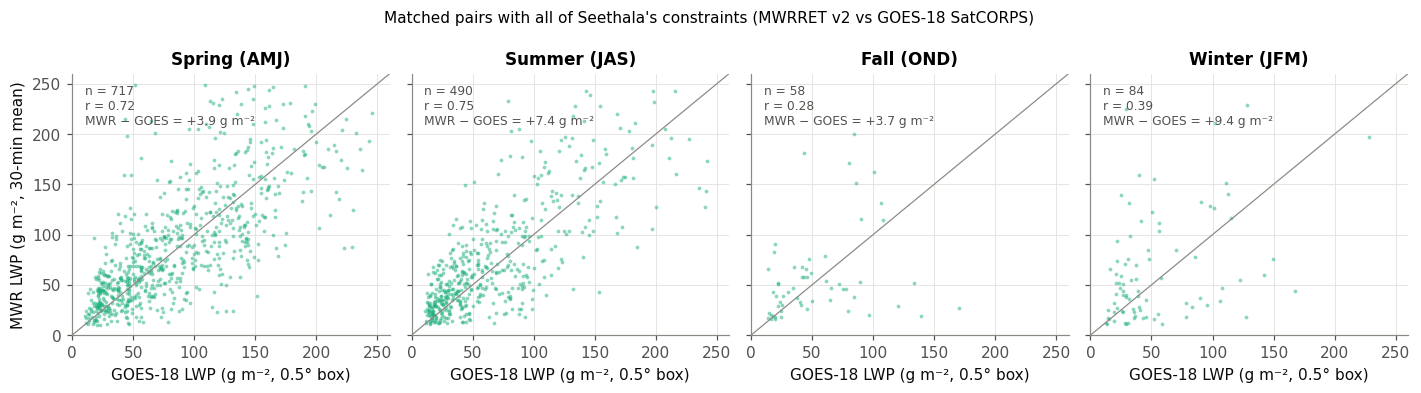

Saved /Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/comparisons/lwp_mwr_vs_goes/figures/mwr_vs_goes18_matched_pairs_by_season.png


In [8]:
# =============================================================================
# Section 5: MWR vs GOES-18 scatter of the matched pairs, by season
# =============================================================================
sel = PAIRS[KEEP]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharex=True, sharey=True)
lim_gm2 = (0, 260)
for ax, season in zip(axes, seasons4):
    s_ = sel[S.season_mask(sel.index, season)]
    ax.plot(lim_gm2, lim_gm2, color=INK_3, lw=0.8)  # 1:1 line
    ax.scatter(s_["goes_lwp_gm2"], s_["mwr_lwp_gm2"], s=6, color=COLORS["MWR"], alpha=0.5, lw=0)
    if len(s_) > 2:
        r_ = np.corrcoef(s_["goes_lwp_gm2"], s_["mwr_lwp_gm2"])[0, 1]
        bias_ = (s_["mwr_lwp_gm2"] - s_["goes_lwp_gm2"]).mean()
        ax.text(0.04, 0.96, f"n = {len(s_)}\nr = {r_:.2f}\nMWR − GOES = {bias_:+.1f} g m⁻²", transform=ax.transAxes,
                va="top", fontsize=8, color=INK_2)
    ax.set_title(f"{season} ({SEETHALA_LABELS[season]})")
    ax.set_xlim(lim_gm2)
    ax.set_ylim(lim_gm2)
    ax.set_xlabel("GOES-18 LWP (g m⁻², 0.5° box)")
axes[0].set_ylabel("MWR LWP (g m⁻², 30-min mean)")
fig.suptitle("Matched pairs with all of Seethala's constraints (MWRRET v2 vs GOES-18 SatCORPS)", fontsize=10)
fig.tight_layout()
plt.show()
fig_path = FIG_DIR / "mwr_vs_goes18_matched_pairs_by_season.png"
fig.savefig(fig_path, dpi=200, bbox_inches="tight")
print(f"Saved {fig_path}")

## 6. Findings (run of 19 Oct 2026; re-check the tables above after changing any setting)

* **Her MWR statistic is reproduced to within 1–8 g m⁻²** by matching the MWR to GOES-18 image times that pass every constraint: annual 81 vs 79, AMJ 89 vs 90, JAS 75 vs 69, OND 57 vs 52, JFM 64 vs 72. Section 3d of the seasonal-averages notebook used ground-based stand-ins and no GOES-18 data, and it was 9–22 g m⁻² lower. The matching is what was missing.
* **Our GOES-18 statistic matches hers in spring, summer and winter (−5 to +3 g m⁻²), but not in fall:** 54 here vs 34 for her. Our box is the 0.5° ARM grid, ~6× her 0.2° box in area and about half land. The fall sample is small (58 pairs here), so box choice can move it a lot. Her fall std of 20 vs our 36 also points to a different set of scenes.
* **The MWR − GOES-18 gap is smaller with this box:** +4 (fall) and +9 g m⁻² (winter) here, against her +18 and +20. The fall and winter gaps in her table may come partly from the box rather than from the MWR. This is inference: n = 58 and 84 pairs, and we do not have her 0.2° file.
* **Which constraints matter:** SZA < 70° removes most pairs (4401 → 1605) and lowers the MWR means. The KAZR CTH rule (a low-topped KAZR layer must exist in the window) raises them: dropping it gives 73/83/68/43/57 g m⁻². Once the GOES-18 constraints apply, the MWR rain sensor screen, the CFF definition (2 km, 3.5 km or any base) and the GOES cloud kind for COD/CTH change nothing. A Parsivel ±30-min screen lowers winter by 6 g m⁻².
* **Open questions for Seethala:** (1) which precipitation fields she used; (2) whether she requires a KAZR layer topped ≤ 2 km in the half hour; (3) how her 30-min bins align with the image times; (4) whether her 0.2° file is available, or how it was made from the SatCORPS pixels.